In [1]:
# Comentarios para Google Colab:
# 1) Monta Google Drive y ajusta rutas:
from google.colab import drive
drive.mount('/content/drive')
BASE_DATA_DIR = "/content/drive/MyDrive/TEG02-2025Arellano/Data"
GLICKO_REPO_PATH = "/content/drive/MyDrive/TEG02-2025Arellano/Data/GlickoSoccer-master"
# 2) Verifica dependencias si hace falta:
!pip install lightgbm scikit-learn seaborn joblib confz
# torch y tensorflow dependen del runtime seleccionado en Colab

Mounted at /content/drive


In [2]:
# === Selector de modo de entrenamiento ===
# Modos disponibles: "sanity" | "fast" | "deep" | "exhaustive"
TRAINING_MODE = "deep"  # cambia aqui segun lo que quieras ejecutar

# Comentarios para Google Colab:
# 1) Monta Google Drive y ajusta rutas:
#    from google.colab import drive
#    drive.mount('/content/drive')
#    BASE_DATA_DIR = "/content/drive/MyDrive/TEG/AplanarDatos"
#    GLICKO_REPO_PATH = "/content/drive/MyDrive/Glicko2Soccer/GlickoSoccer-master"
# 2) Verifica dependencias si hace falta:
#    !pip install lightgbm scikit-learn seaborn joblib
#    # torch y tensorflow dependen del runtime seleccionado en Colab

# Rutas base (ajusta si estas en Colab)
#BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
#GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"

# Flags globales controlados por el selector
# Por seguridad inicializamos las banderas
RUN_FULL_TRAINING = False
RUN_SANITY_CHECK = False
FAST_MODE = False
EXHAUSTIVE_MODE = False
DEBUG_MODE = False

# Semilla global para reproducibilidad
Seed = 42

if TRAINING_MODE == "sanity":
    # Sanity: no ejecutar todo el entrenamiento largo; se usa DEBUG_MODE para
    # ejecutar el proceso completo pero sobre un subconjunto (df.head(100)).
    RUN_FULL_TRAINING = False
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = True
elif TRAINING_MODE == "fast":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = True
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = False
elif TRAINING_MODE == "deep":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = False
elif TRAINING_MODE == "exhaustive":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = True
    DEBUG_MODE = False
else:
    raise ValueError(f"TRAINING_MODE invalido: {TRAINING_MODE}")

#BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
DATASET_MODE = "full_lite_recortado"   # o "lite", "full", "full_lite"
DEBUG_MODE = False

In [3]:
import sys
import os
import json
import time
import math
import importlib
import random
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, log_loss, accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from scipy.special import iv, gammaln
from scipy.optimize import minimize
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Optional ML frameworks (keep notebook import-safe)
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
except Exception:
    torch = None
    nn = None
    Dataset = None
    DataLoader = None

try:
    import tensorflow as tf
    from tensorflow import keras
except Exception:
    tf = None
    keras = None

# Workspace path for GlickoSoccer repo (needed before importing modules from it)
#if "GLICKO_REPO_PATH" not in globals():
    #GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"
if not os.path.exists(GLICKO_REPO_PATH):
    raise FileNotFoundError(
        "No se encontro el repo GlickoSoccer. Ajusta GLICKO_REPO_PATH en el selector de modo."
    )
sys.path.insert(0, GLICKO_REPO_PATH)

# Local modules
from G2Av1513 import Glicko2G2A, RatingG2A
from soccer.glicko_soccer import GlickoSoccer
import glicko2 as glicko2_lib

In [4]:
import sys
import os
import json
import time
import math
import importlib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, log_loss, accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from scipy.special import iv, gammaln
from scipy.optimize import minimize
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Optional ML frameworks (keep notebook import-safe)
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
except Exception:
    torch = None
    nn = None
    Dataset = None
    DataLoader = None

try:
    import tensorflow as tf
    from tensorflow import keras
except Exception:
    tf = None
    keras = None

# Workspace path for GlickoSoccer repo (needed before importing modules from it)
#if "GLICKO_REPO_PATH" not in globals():
    #GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"
if not os.path.exists(GLICKO_REPO_PATH):
    raise FileNotFoundError(
        "No se encontro el repo GlickoSoccer. Ajusta GLICKO_REPO_PATH en el selector de modo."
    )
sys.path.insert(0, GLICKO_REPO_PATH)

# Local modules
from G2Av1513 import Glicko2G2A, RatingG2A
from soccer.glicko_soccer import GlickoSoccer
import glicko2 as glicko2_lib

# Carga de los CSV
#if "BASE_DATA_DIR" not in globals():
    #BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
if "DATASET_MODE" not in globals():
    DATASET_MODE = "full_lite_recortado"
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False

DATASET_OPTIONS = {
    "full": ["df_full"],
    "lite": ["df_lite"],
    "full_lite": ["df_full", "df_lite"],
    "full_lite_recortado": ["df_full", "df_lite", "df_lite_recortado"],
}
if DATASET_MODE not in DATASET_OPTIONS:
    raise ValueError(
        f"DATASET_MODE invalido: {DATASET_MODE}. Opciones validas: {list(DATASET_OPTIONS)}"
    )


def resolve_path(candidates):
    for path in candidates:
        if path and os.path.exists(path):
            return path
    joined = "\n".join([str(p) for p in candidates])
    raise FileNotFoundError(
        "No se encontro ningun dataset. Revisa BASE_DATA_DIR y los nombres.\n" + joined
    )


# Datasets base
ruta_lite = resolve_path([
    os.path.join(BASE_DATA_DIR, "matches_final_model_clean2.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_clean_scaled.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_clean.csv"),
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean2.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean.csv",
])
ruta_full = resolve_path([
    os.path.join(BASE_DATA_DIR, "matches_final_model_full2.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_full_scaled.csv"),
    #os.path.join(BASE_DATA_DIR, "matches_final_model_full.csv"),
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full2.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled.csv",
    #r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full.csv",
])

df_lite = pd.read_csv(ruta_lite)
df_full = pd.read_csv(ruta_full)


def _get_date_series(df, date_col='match_date_from_id'):
    if date_col not in df.columns:
        raise ValueError(f"Falta columna {date_col}")
    dt = pd.to_datetime(df[date_col], errors='coerce')
    if dt.notna().mean() < 0.5:
        dt = pd.to_numeric(df[date_col], errors='coerce')
    return dt


def _extract_match_id_ymd(df, id_col='match_id_new'):
    if id_col not in df.columns:
        raise ValueError(f"Falta columna {id_col}")
    s = df[id_col].astype(str).str.slice(0, 8)
    y = pd.to_numeric(s.str.slice(0, 4), errors='coerce')
    m = pd.to_numeric(s.str.slice(4, 6), errors='coerce')
    d = pd.to_numeric(s.str.slice(6, 8), errors='coerce')
    return y, m, d


def add_pandemic_and_season(df):
    df2 = df.copy()
    dt = _get_date_series(df2)
    dt_series = pd.to_datetime(dt, errors='coerce')
    y_mid, m_mid, d_mid = _extract_match_id_ymd(df2)
    dt_fallback = pd.to_datetime(
        y_mid.astype('Int64') * 10000 + m_mid.astype('Int64') * 100 + d_mid.astype('Int64'),
        format='%Y%m%d', errors='coerce'
    )
    dt_series = dt_series.fillna(dt_fallback)
    start = pd.Timestamp('2020-03-03')
    end = pd.Timestamp('2021-06-06')
    df2['pandemic'] = ((dt_series >= start) & (dt_series <= end)).astype(int)

    calendar_europe = [
        "Bundesliga",
        "ChampionsLeague",
        "EuropaLeague",
        "EuropaConferenceLeague",
        "LaLiga",
        "LigaMX",
        "Ligue1",
        "PremierLeague",
        "SaudiProLeague",
        "SerieA",
        "SuperLeagueGreece",
    ]
    afc_winter = ["AFCChampionsLeagueElite", "AFCChampionsTwo"]
    comp = df2['Competition'].astype(str)
    y = y_mid.fillna(dt_series.dt.year)
    m = m_mid.fillna(dt_series.dt.month)
    is_winter = comp.isin(calendar_europe)
    is_winter |= (comp == 'LigaArgentina') & (y <= 2020)
    is_winter |= comp.isin(afc_winter) & (y >= 2023)
    season = y.copy()
    season = np.where(is_winter & (m >= 8), y + 1, season)
    df2['season'] = pd.Series(season, index=df2.index, dtype="Int64")
    return df2


def build_lite_recortado(df_lite_source, df_full_source):
    if 'match_id_new' not in df_lite_source.columns or 'match_id_new' not in df_full_source.columns:
        raise ValueError("Para construir df_lite_recortado se requiere la columna match_id_new en ambos datasets")
    common_match_ids = pd.Index(df_full_source['match_id_new'].dropna().unique())
    return df_lite_source.loc[df_lite_source['match_id_new'].isin(common_match_ids)].copy()


df_lite_recortado = build_lite_recortado(df_lite, df_full)

df_lite = add_pandemic_and_season(df_lite)
df_full = add_pandemic_and_season(df_full)
df_lite_recortado = add_pandemic_and_season(df_lite_recortado)

DATASET_REGISTRY = {
    "df_lite": df_lite,
    "df_full": df_full,
    "df_lite_recortado": df_lite_recortado,
}
ACTIVE_DATASET_NAMES = DATASET_OPTIONS[DATASET_MODE]
ACTIVE_DATASETS = {name: DATASET_REGISTRY[name] for name in ACTIVE_DATASET_NAMES}


def chronological_split_by_ratio(df, ratio=0.7):
    """Divide el DataFrame manteniendo el orden cronologico (por match_date_from_id)."""
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    return train_df, test_df


def _ensure_non_empty_split(df_sorted, train_df, test_df):
    if len(df_sorted) >= 2 and (len(train_df) == 0 or len(test_df) == 0):
        train_df = df_sorted.iloc[:-1].copy()
        test_df = df_sorted.iloc[-1:].copy()
    return train_df, test_df


def safe_pct(part, total):
    return (part / total * 100.0) if total else 0.0


train_df_lite_ratio = None
test_df_lite_ratio = None
train_df_full_ratio = None
test_df_full_ratio = None
train_df_lite_recortado_ratio = None
test_df_lite_recortado_ratio = None

for dataset_name, dataset_df in DATASET_REGISTRY.items():
    train_df, test_df = chronological_split_by_ratio(dataset_df, ratio=0.7)
    if DEBUG_MODE:
        df_sorted = dataset_df.sort_values('match_date_from_id').reset_index(drop=True)
        train_df, test_df = _ensure_non_empty_split(df_sorted, train_df, test_df)
    if dataset_name == 'df_lite':
        train_df_lite_ratio, test_df_lite_ratio = train_df, test_df
    elif dataset_name == 'df_full':
        train_df_full_ratio, test_df_full_ratio = train_df, test_df
    elif dataset_name == 'df_lite_recortado':
        train_df_lite_recortado_ratio, test_df_lite_recortado_ratio = train_df, test_df
    print(
        f"{dataset_name} (ratio 70/30) - Entrenamiento: {len(train_df)} ({safe_pct(len(train_df), len(dataset_df)):.1f}%) | "
        f"Prueba: {len(test_df)} ({safe_pct(len(test_df), len(dataset_df)):.1f}%)"
    )

print(f"Modo activo: {DATASET_MODE}")
print(f"Datasets activos: {', '.join(ACTIVE_DATASET_NAMES)}")


df_lite (ratio 70/30) - Entrenamiento: 24940 (70.0%) | Prueba: 10689 (30.0%)
df_full (ratio 70/30) - Entrenamiento: 17555 (70.0%) | Prueba: 7524 (30.0%)
df_lite_recortado (ratio 70/30) - Entrenamiento: 17555 (70.0%) | Prueba: 7524 (30.0%)
Modo activo: full_lite_recortado
Datasets activos: df_full, df_lite, df_lite_recortado


In [5]:
# Columnas a excluir
exclude_cols = ['match_id_new', 'match_date_from_id', 'Competition',
           'home_team', 'away_team', 'home_team_id', 'away_team_id',
           'home_goals', 'away_goals', 'home_Goals', 'away_Goals',
           'draw_prob', 'mu_home', 'mu_away', 'year_from_id', 'month_from_id',
           'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2',
           'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign',
           'home_OccRat', 'season', 'pandemic', 'home_score', 'away_score', 'outcome']  # draw_prob aún no existe

def get_feature_cols(df):
    """Devuelve lista de columnas numéricas que no están en exclude_cols"""
    return [col for col in df.columns
            if col not in exclude_cols and pd.api.types.is_numeric_dtype(df[col])]

# Verificamos para lite, full y recortado
features_lite = get_feature_cols(df_lite)
print(f"Lite: {len(features_lite)} features")
print("Features:", features_lite[:])

features_full = get_feature_cols(df_full)
print(f"Full: {len(features_full)} features")
print("Features:", features_full[:])

features_lite_recortado = get_feature_cols(df_lite_recortado)
print(f"Lite recortado: {len(features_lite_recortado)} features")
print("Features:", features_lite_recortado[:])


Lite: 33 features
Features: ['travel_km', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30', 'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10', 'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30', 'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10', 'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30']
Full: 33 features
Features: ['travel_km', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_h

In [6]:
# --- Bloque: Skellam + LGBM (definiciones) ---
rolling_features = [
    'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10',
    'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30',
    'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10',
    'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30',
    'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10',
    'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30',
    'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10',
    'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30',
 ]

def get_rolling_features(df):
    cols = [c for c in rolling_features if c in df.columns]
    if len(cols) != len(rolling_features):
        missing = [c for c in rolling_features if c not in df.columns]
        print("Advertencia: faltan rolling features:", missing)
    return cols

def skellam_draw_prob(mu1, mu2):
    """Probabilidad de empate según distribución de Skellam (k=0)."""
    mu1 = np.maximum(mu1, 0.0)
    mu2 = np.maximum(mu2, 0.0)
    x = 2 * np.sqrt(mu1 * mu2)
    x = np.clip(x, 0, 700)
    return np.exp(-(mu1 + mu2)) * iv(0, x)

def train_lgbm_and_add_draw_prob(
    train_df,
    test_df,
    model_prefix,
    feature_cols,
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    early_stopping_rounds=10,
    log_eval=50,
 ):
    """Entrena LightGBM (Poisson) y agrega mu_home, mu_away y draw_prob."""
    if not feature_cols:
        raise ValueError("feature_cols esta vacio")
    train_df = train_df.copy()
    test_df = test_df.copy()

    # Split interno de validacion (para early stopping sin tocar el test)
    if 'match_date_from_id' in train_df.columns:
        train_df = train_df.sort_values('match_date_from_id').reset_index(drop=True)
    val_ratio = 0.1
    n_val = max(1, int(len(train_df) * val_ratio)) if len(train_df) >= 10 else 0
    if n_val > 0:
        val_df = train_df.iloc[-n_val:].copy()
        train_main = train_df.iloc[:-n_val].copy()
    else:
        val_df = None
        train_main = train_df

    X_train = train_main[feature_cols]
    y_home_train = train_main['home_goals']
    y_away_train = train_main['away_goals']
    X_test = test_df[feature_cols]

    print(f"\n--- {model_prefix} ---")
    print(f"Entrenamiento: {len(train_df)} partidos | Prueba: {len(test_df)} partidos")

    if val_df is not None:
        X_val = val_df[feature_cols]
        y_home_val = val_df['home_goals']
        y_away_val = val_df['away_goals']
        eval_set_home = [(X_val, y_home_val)]
        eval_set_away = [(X_val, y_away_val)]
        callbacks = [lgb.early_stopping(early_stopping_rounds), lgb.log_evaluation(log_eval)]
    else:
        eval_set_home = None
        eval_set_away = None
        callbacks = [lgb.log_evaluation(log_eval)]

    model_home = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
        random_state=42, verbose=-1
    )
    model_home.fit(
        X_train, y_home_train,
        eval_set=eval_set_home,
        callbacks=callbacks
    )

    model_away = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
        random_state=42, verbose=-1
    )
    model_away.fit(
        X_train, y_away_train,
        eval_set=eval_set_away,
        callbacks=callbacks
    )

    # Predecir y calcular draw_prob
    X_train_full = train_df[feature_cols]
    train_df['mu_home'] = model_home.predict(X_train_full)
    train_df['mu_away'] = model_away.predict(X_train_full)
    train_df['draw_prob'] = train_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )

    test_df['mu_home'] = model_home.predict(X_test)
    test_df['mu_away'] = model_away.predict(X_test)
    test_df['draw_prob'] = test_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )

    full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

    joblib.dump(model_home, f"{model_prefix}_home_model.pkl")
    joblib.dump(model_away, f"{model_prefix}_away_model.pkl")
    print(f"Modelos guardados: {model_prefix}_home/away_model.pkl")

    return full_df, model_home, model_away

In [7]:
# --- Bloque: Glicko (definiciones) ---
def prepare_for_glicko(df):
    df2 = df.copy()
    # match_id (unico)
    if 'match_id_new' not in df2.columns:
        df2['match_id_new'] = range(len(df2))

    # Fecha y season
    try:
        df2['season'] = df2['match_id_new'].astype(str).str[:4].astype(int)
    except:
        df2['match_date_from_id'] = pd.to_datetime(df2['match_date_from_id'], errors='coerce')
        df2['season'] = df2['match_date_from_id'].dt.year

    # Verificar seasons nulas
    if df2['season'].isna().any():
        print("Advertencia: algunos partidos no tienen anio asignado. Se rellenan con 1900")
        df2['season'] = df2['season'].fillna(1900).astype(int)

    # tournament_type: 1 = liga (por defecto)
    df2['tournament_type'] = 1
    continental_keywords = [
        'ChampionsLeague', 'EuropaLeague', 'EuropaConferenceLeague',
        'AFCChampionsLeagueElite', 'AFCChampionsTwo', 'CONCACAFChampionsLeague', 'FIFAClubWorldCup',
        'CopaLibertadores', 'CopaSudamericana',
    ]
    mask = df2['Competition'].str.contains('|'.join(continental_keywords), case=False, na=False)
    df2.loc[mask, 'tournament_type'] = 3

    # outcome
    df2['outcome'] = np.where(df2['home_goals'] > df2['away_goals'], 'H',
                              np.where(df2['home_goals'] < df2['away_goals'], 'A', 'D'))

    # is_pandemic
    if 'is_pandemic' in df2.columns:
        df2['is_pandemic'] = df2['is_pandemic'].astype(bool)
    else:
        df2['is_pandemic'] = False

    # draw_probability (probabilidad cruda)
    df2['draw_probability'] = df2['draw_prob'].fillna(0.26)

    # tournament (nombre competicion)
    df2['tournament'] = df2['Competition']

    return df2

def prepare_glicko_input(df):
    df_prep = prepare_for_glicko(df)
    df_prep = df_prep.rename(columns={
        'match_date_from_id': 'date',
        'match_id_new': 'match_id',
    })
    assert 'date' in df_prep.columns, "Falta columna 'date'"
    assert 'match_id' in df_prep.columns, "Falta columna 'match_id'"
    return df_prep

In [8]:
# Importante, aqui definimos como evaluar el modelo Skellam/LGBM

def evaluate_model(train_df, test_df, model_home, model_away, feature_cols, dataset_name):
    """
    Evalua los modelos por separado en train/test usando el split 70/30.
    """
    X_train = train_df[feature_cols]
    y_home_train = train_df['home_goals']
    y_away_train = train_df['away_goals']
    X_test = test_df[feature_cols]
    y_home_test = test_df['home_goals']
    y_away_test = test_df['away_goals']

    mu_home_train = model_home.predict(X_train)
    mu_away_train = model_away.predict(X_train)
    mu_home_test = model_home.predict(X_test)
    mu_away_test = model_away.predict(X_test)

    mae_home_train = mean_absolute_error(y_home_train, mu_home_train)
    mae_away_train = mean_absolute_error(y_away_train, mu_away_train)
    mae_home_test = mean_absolute_error(y_home_test, mu_home_test)
    mae_away_test = mean_absolute_error(y_away_test, mu_away_test)

    draw_prob_train = skellam_draw_prob(mu_home_train, mu_away_train)
    draw_prob_test = skellam_draw_prob(mu_home_test, mu_away_test)

    real_draw_train = (y_home_train == y_away_train).astype(int)
    real_draw_test = (y_home_test == y_away_test).astype(int)

    def log_loss_binary(prob_draw, y_true):
        prob_draw = np.clip(prob_draw, 1e-15, 1 - 1e-15)
        return -np.mean(y_true * np.log(prob_draw) + (1 - y_true) * np.log(1 - prob_draw))

    log_loss_train = log_loss_binary(draw_prob_train, real_draw_train)
    log_loss_test = log_loss_binary(draw_prob_test, real_draw_test)

    freq_draw_train = real_draw_train.mean()
    freq_draw_test = real_draw_test.mean()
    mean_pred_draw_train = draw_prob_train.mean()
    mean_pred_draw_test = draw_prob_test.mean()

    print(f"\n========== {dataset_name.upper()} ==========")
    print(f"MAE home  - train: {mae_home_train:.4f} | test: {mae_home_test:.4f}")
    print(f"MAE away  - train: {mae_away_train:.4f} | test: {mae_away_test:.4f}")
    print(f"LogLoss draw - train: {log_loss_train:.6f} | test: {log_loss_test:.6f}")
    print(f"Frecuencia empate real   - train: {freq_draw_train:.4f} | test: {freq_draw_test:.4f}")
    print(f"Prob. empate pred. media - train: {mean_pred_draw_train:.4f} | test: {mean_pred_draw_test:.4f}")

    return {
        'mae_home_train': mae_home_train, 'mae_home_test': mae_home_test,
        'mae_away_train': mae_away_train, 'mae_away_test': mae_away_test,
        'log_loss_train': log_loss_train, 'log_loss_test': log_loss_test,
        'freq_draw_train': freq_draw_train, 'freq_draw_test': freq_draw_test,
        'mean_pred_draw_train': mean_pred_draw_train, 'mean_pred_draw_test': mean_pred_draw_test
    }

In [9]:
# Esto es para medir su calibracion

def plot_calibration(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)
    draw_prob = skellam_draw_prob(mu_home, mu_away)
    real_draw = (test_df['home_goals'] == test_df['away_goals']).astype(int)

    bins = np.linspace(0, 1, 11)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    observed = []
    for i in range(len(bins) - 1):
        mask = (draw_prob >= bins[i]) & (draw_prob < bins[i + 1])
        if mask.sum() > 0:
            observed.append(real_draw[mask].mean())
        else:
            observed.append(np.nan)

    plt.figure(figsize=(6, 5))
    plt.plot(bin_centers, observed, 'o-', label='Observado')
    plt.plot([0, 1], [0, 1], 'k--', label='Perfectamente calibrado')
    plt.xlabel('Probabilidad de empate predicha')
    plt.ylabel('Frecuencia real de empate')
    plt.title(f'Calibracion de draw_prob - {dataset_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

In [10]:
# Definimos los residuales
def plot_residuals(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    y_home_true = test_df['home_goals']
    y_away_true = test_df['away_goals']
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)

    resid_home = y_home_true - mu_home
    resid_away = y_away_true - mu_away

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(resid_home, bins=20, alpha=0.7, label='Home')
    axes[0].set_title(f'{dataset_name} - Residuos goles locales')
    axes[0].axvline(0, color='red', linestyle='--')
    axes[1].hist(resid_away, bins=20, alpha=0.7, label='Away', color='orange')
    axes[1].set_title(f'{dataset_name} - Residuos goles visitantes')
    axes[1].axvline(0, color='red', linestyle='--')
    plt.tight_layout()
    plt.show()

    print(f"Residuos home - media: {resid_home.mean():.3f}, std: {resid_home.std():.3f}")
    print(f"Residuos away - media: {resid_away.mean():.3f}, std: {resid_away.std():.3f}")

[Skellam/LGBM] DATASET_MODE=full_lite_recortado | Datasets activos: ['full', 'lite', 'lite_recortado']

--- full_ratio ---
Entrenamiento: 17555 partidos | Prueba: 7524 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.970898
[100]	valid_0's l1: 0.960151
[150]	valid_0's l1: 0.959124
Early stopping, best iteration is:
[144]	valid_0's l1: 0.959056
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.85941
Early stopping, best iteration is:
[40]	valid_0's l1: 0.859089
Modelos guardados: full_ratio_home/away_model.pkl

--- lite_ratio ---
Entrenamiento: 24940 partidos | Prueba: 10689 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.940708
[100]	valid_0's l1: 0.928398
[150]	valid_0's l1: 0.927148
Early stopping, best iteration is:
[140]	valid_0's l1: 0.927135
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[38]	valid_0's l1: 0.812207
M

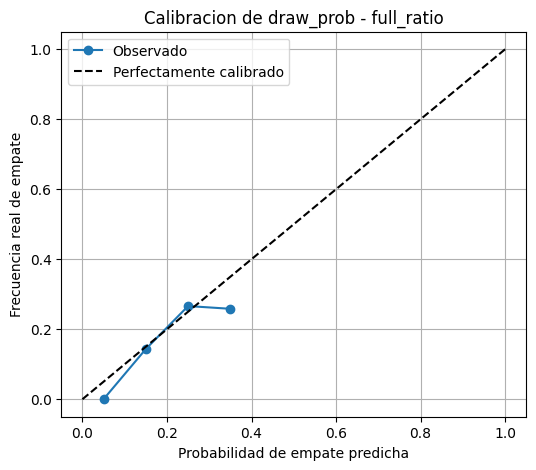

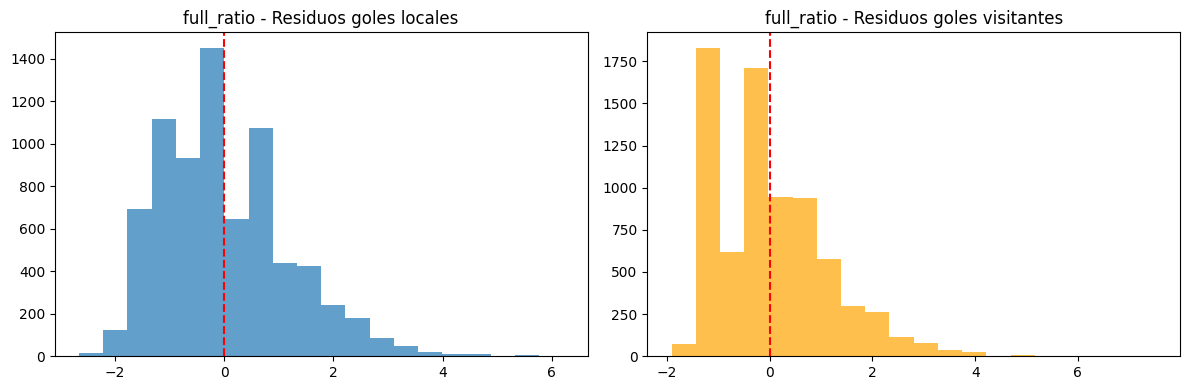

Residuos home - media: 0.004, std: 1.171
Residuos away - media: 0.027, std: 1.083


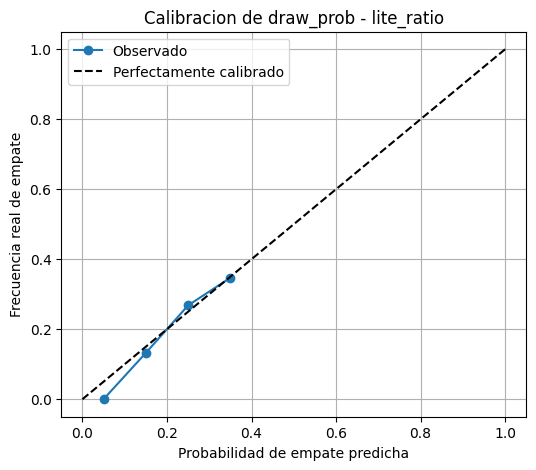

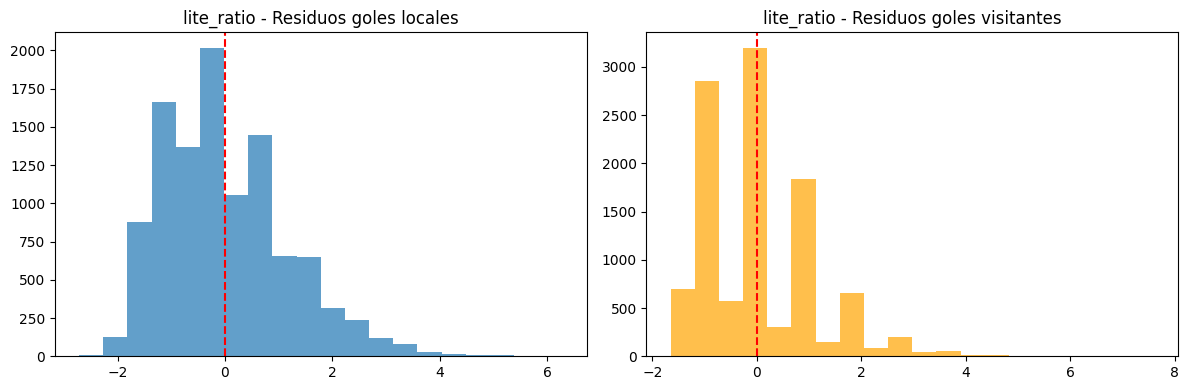

Residuos home - media: 0.002, std: 1.164
Residuos away - media: 0.022, std: 1.079


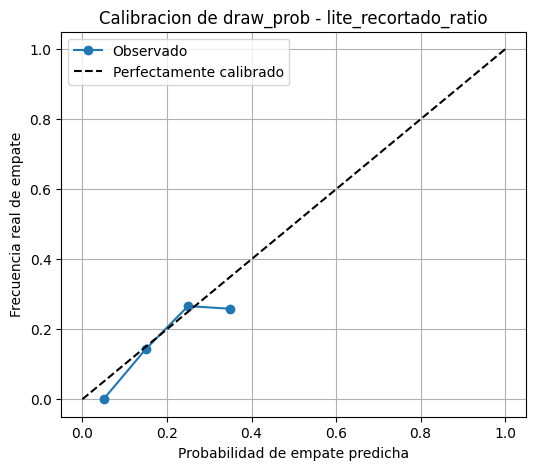

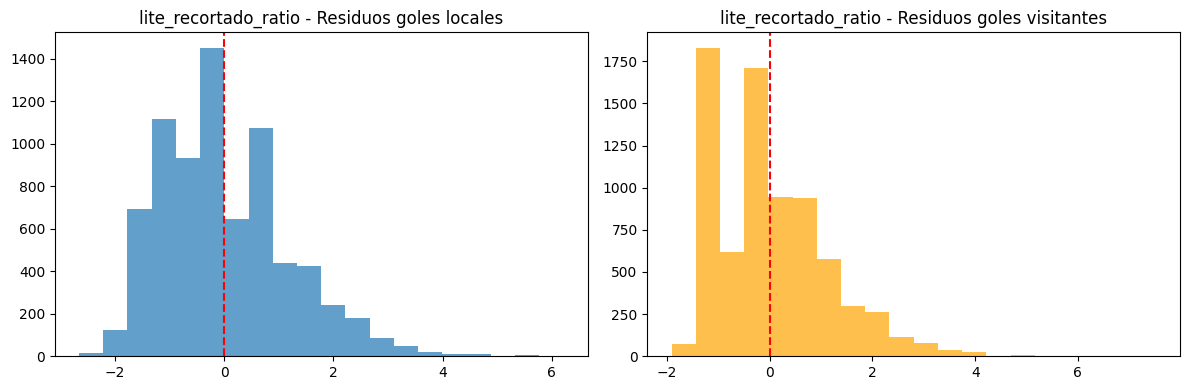

Residuos home - media: 0.004, std: 1.171
Residuos away - media: 0.027, std: 1.083


In [11]:
# === Skellam/LGBM (entrenamientos, calibracion y graficos) ===

# Controles globales (se comparten con el resto de bloques)
if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "RUN_SANITY_CHECK" not in globals():
    RUN_SANITY_CHECK = True
if "FAST_MODE" not in globals():
    FAST_MODE = True
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False
if "PARALLEL_SKELLAM" not in globals():
    PARALLEL_SKELLAM = False
if "N_JOBS" not in globals():
    _cpu = os.cpu_count() or 2
    N_JOBS = max(1, _cpu - 1)
if "Seed" not in globals():
    Seed = 42

random.seed(Seed)
np.random.seed(Seed)
if tf is not None:
    tf.random.set_seed(Seed)
if torch is not None:
    torch.manual_seed(Seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(Seed)
    try:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass

# Skellam/LGBM siempre se ejecuta para generar dataset_draw_ratio
RUN_SKELLAM_LGBM = True

# Resolver datasets activos a partir de DATASET_MODE (definido en celda 4)
name_map = {
    "df_lite": "lite",
    "df_full": "full",
    "df_lite_recortado": "lite_recortado",
}
reverse_map = {v: k for k, v in name_map.items()}
active_short_names = []
if "ACTIVE_DATASET_NAMES" in globals():
    active_short_names = [name_map[n] for n in ACTIVE_DATASET_NAMES if n in name_map]
if not active_short_names:
    active_short_names = ["lite"]

ratio_split_map = {
    "lite": (train_df_lite_ratio, test_df_lite_ratio),
    "full": (train_df_full_ratio, test_df_full_ratio),
    "lite_recortado": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
}
frame_map = {
    "lite": df_lite,
    "full": df_full,
    "lite_recortado": df_lite_recortado,
}

datasets = {}
dataset_frames = {}
for dataset_name in active_short_names:
    train_test = ratio_split_map.get(dataset_name)
    if train_test is None:
        continue
    train_df, test_df = train_test
    if train_df is None or test_df is None:
        continue
    datasets[dataset_name] = {"ratio": (train_df, test_df)}
    dataset_frames[dataset_name] = frame_map[dataset_name]

if not datasets:
    raise ValueError("No hay datasets activos con split ratio preparado. Ejecuta primero la celda 4.")

print(f"[Skellam/LGBM] DATASET_MODE={DATASET_MODE} | Datasets activos: {list(datasets.keys())}")

dataset_draw_ratio = None
skellam_results = None

# Parametros de entrenamiento
if FAST_MODE:
    LGBM_N_ESTIMATORS = 80
    LGBM_LR = 0.08
    LGBM_MAX_DEPTH = 4
    LGBM_EARLY_STOP = 5
    LGBM_LOG_EVAL = 100
else:
    LGBM_N_ESTIMATORS = 200
    LGBM_LR = 0.05
    LGBM_MAX_DEPTH = 5
    LGBM_EARLY_STOP = 10
    LGBM_LOG_EVAL = 50

def _skellam_job(dataset_name, split_name, train_df, test_df):
    feature_cols = get_rolling_features(train_df)
    model_prefix = f"{dataset_name}_{split_name}"
    df_with_draw, model_home, model_away = train_lgbm_and_add_draw_prob(
        train_df,
        test_df,
        model_prefix,
        feature_cols,
        n_estimators=LGBM_N_ESTIMATORS,
        learning_rate=LGBM_LR,
        max_depth=LGBM_MAX_DEPTH,
        early_stopping_rounds=LGBM_EARLY_STOP,
        log_eval=LGBM_LOG_EVAL,
    )
    return dataset_name, split_name, df_with_draw, model_home, model_away

if RUN_SKELLAM_LGBM:
    skellam_results = {}
    if PARALLEL_SKELLAM:
        jobs = []
        for dataset_name, splits in datasets.items():
            for split_name, (train_df, test_df) in splits.items():
                jobs.append((dataset_name, split_name, train_df, test_df))
        results = joblib.Parallel(n_jobs=N_JOBS)(
            joblib.delayed(_skellam_job)(dataset_name, split_name, train_df, test_df)
            for dataset_name, split_name, train_df, test_df in jobs
        )
        for dataset_name, split_name, df_with_draw, model_home, model_away in results:
            skellam_results[(dataset_name, split_name)] = {
                "df_with_draw": df_with_draw,
                "model_home": model_home,
                "model_away": model_away,
            }
    else:
        for dataset_name, splits in datasets.items():
            for split_name, (train_df, test_df) in splits.items():
                feature_cols = get_rolling_features(train_df)
                model_prefix = f"{dataset_name}_{split_name}"
                df_with_draw, model_home, model_away = train_lgbm_and_add_draw_prob(
                    train_df,
                    test_df,
                    model_prefix,
                    feature_cols,
                    n_estimators=LGBM_N_ESTIMATORS,
                    learning_rate=LGBM_LR,
                    max_depth=LGBM_MAX_DEPTH,
                    early_stopping_rounds=LGBM_EARLY_STOP,
                    log_eval=LGBM_LOG_EVAL,
                )
                skellam_results[(dataset_name, split_name)] = {
                    "df_with_draw": df_with_draw,
                    "model_home": model_home,
                    "model_away": model_away,
                }

    eval_targets = [(dataset_name, "ratio") for dataset_name in datasets.keys()]

    for dataset_name, split_name in eval_targets:
        df_with_draw = skellam_results[(dataset_name, split_name)]["df_with_draw"]
        desc = df_with_draw["draw_prob"].describe()
        print(f"\n[{dataset_name}/{split_name}] draw_prob stats:")
        print(desc)

    # Guardar salidas por dataset activo
    out_name_map = {
        "lite": "matches_final_model_clean_with_draw_ratio.csv",
        "full": "matches_final_model_full_with_draw_ratio.csv",
        "lite_recortado": "matches_final_model_clean_recortado_with_draw_ratio.csv",
    }
    dataset_draw_ratio = {}
    for dataset_name, _ in eval_targets:
        df_with_draw = skellam_results[(dataset_name, "ratio")]["df_with_draw"]
        dataset_draw_ratio[dataset_name] = df_with_draw
        out_path = os.path.join(BASE_DATA_DIR, out_name_map[dataset_name])
        df_with_draw.to_csv(out_path, index=False)
        print(f"[{dataset_name}] guardado en: {out_path}")
        print(f"[{dataset_name}] draw_prob (primeros 5):")
        print(df_with_draw[["home_goals", "away_goals", "draw_prob"]].head())

    # Exponer variables de compatibilidad hacia celdas posteriores
    if "lite" in dataset_draw_ratio:
        df_lite_reentrenado = dataset_draw_ratio["lite"]
    if "full" in dataset_draw_ratio:
        df_full_reentrenado = dataset_draw_ratio["full"]
    if "lite_recortado" in dataset_draw_ratio:
        df_lite_recortado_reentrenado = dataset_draw_ratio["lite_recortado"]

    # Evaluacion MAE + logloss (resumen conjunto)
    metrics_rows = []
    for dataset_name, split_name in eval_targets:
        train_df, test_df = datasets[dataset_name][split_name]
        feature_cols = get_rolling_features(train_df)
        model_home = skellam_results[(dataset_name, split_name)]["model_home"]
        model_away = skellam_results[(dataset_name, split_name)]["model_away"]
        metrics = evaluate_model(
            train_df, test_df, model_home, model_away, feature_cols, f"{dataset_name}_{split_name}"
        )
        metrics_rows.append({
            "dataset": dataset_name,
            "split": split_name,
            "mae_home_test": metrics["mae_home_test"],
            "mae_away_test": metrics["mae_away_test"],
            "log_loss_test": metrics["log_loss_test"],
            "mean_pred_draw_test": metrics["mean_pred_draw_test"],
        })

    metrics_skellam_summary = pd.DataFrame(metrics_rows).sort_values(["dataset", "split"]).reset_index(drop=True)
    print("\n=== Resumen Skellam/LGBM por dataset activo ===")
    print(metrics_skellam_summary)

    # Calibracion y residuos para cada dataset activo (split ratio)
    for dataset_name, _ in eval_targets:
        train_df, test_df = datasets[dataset_name]["ratio"]
        feature_cols = get_rolling_features(train_df)
        model_home = skellam_results[(dataset_name, "ratio")]["model_home"]
        model_away = skellam_results[(dataset_name, "ratio")]["model_away"]
        plot_calibration(test_df, model_home, model_away, feature_cols, f"{dataset_name}_ratio")
        plot_residuals(test_df, model_home, model_away, feature_cols, f"{dataset_name}_ratio")
else:
    dataset_draw_ratio = None
    fallback_map = {
        "lite": "df_lite_reentrenado",
        "full": "df_full_reentrenado",
        "lite_recortado": "df_lite_recortado_reentrenado",
    }
    for dataset_name in active_short_names:
        gname = fallback_map.get(dataset_name)
        if gname and gname in globals():
            if dataset_draw_ratio is None:
                dataset_draw_ratio = {}
            dataset_draw_ratio[dataset_name] = globals()[gname]


In [15]:
# === RRNN (entrenamiento separado) ===

if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "FAST_MODE" not in globals():
    FAST_MODE = True
if "EXHAUSTIVE_MODE" not in globals():
    EXHAUSTIVE_MODE = False
if "Seed" not in globals():
    Seed = 42

RUN_RRNN = True
if not RUN_FULL_TRAINING and not DEBUG_MODE:
    RUN_RRNN = False

if RUN_RRNN:
    if dataset_draw_ratio is None:
        print("RRNN omitido: dataset_draw_ratio no disponible")
    elif torch is None:
        print("PyTorch no disponible: se omite RRNN")
    else:
        random.seed(Seed)
        np.random.seed(Seed)
        torch.manual_seed(Seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(Seed)
        if tf is not None:
            tf.random.set_seed(Seed)
        try:
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
        except Exception:
            pass

        for dataset_name, df_rrnn in dataset_draw_ratio.items():
            print(f"\n[RRNN] dataset={dataset_name}")
            df_rrnn = df_rrnn.copy()
            if EXHAUSTIVE_MODE:
                seq_len = 10
                train_ratio = 0.7
                val_ratio = 0.1
                batch_size = 256
                epochs = 60
                lr = 8e-4
                weight_decay = 1e-4
                hidden_size = 128
                dropout = 0.2
            elif FAST_MODE:
                seq_len = 6
                train_ratio = 0.7
                val_ratio = 0.08
                batch_size = 256
                epochs = 8
                lr = 1e-3
                weight_decay = 1e-4
                hidden_size = 48
                dropout = 0.2
            else:
                seq_len = 8
                train_ratio = 0.7
                val_ratio = 0.1
                batch_size = 256
                epochs = 30
                lr = 1e-3
                weight_decay = 1e-4
                hidden_size = 64
                dropout = 0.2
            min_prob = 1e-15

            exclude_cols = [
                "match_id_new", "match_date_from_id", "Competition",
                "home_team", "away_team", "home_team_id", "away_team_id",
                "home_goals", "away_goals", "home_Goals", "away_Goals",
                "year_from_id", "month_from_id",
                "mu_home", "mu_away",
            ]
            numeric_cols = [c for c in df_rrnn.columns if pd.api.types.is_numeric_dtype(df_rrnn[c])]
            feature_cols = [c for c in numeric_cols if c not in exclude_cols]
            if "draw_prob" not in feature_cols and "draw_prob" in df_rrnn.columns:
                feature_cols.append("draw_prob")

            df_rrnn = df_rrnn.sort_values("match_date_from_id").reset_index(drop=True)
            df_rrnn[feature_cols] = df_rrnn[feature_cols].fillna(0.0)

            hist_extra_cols = ["is_home", "goals_for", "goals_against", "result"]
            base_dim = len(feature_cols)
            extra_dim = len(hist_extra_cols)
            hist_dim = base_dim + extra_dim

            def outcome_label(row):
                if row["home_goals"] > row["away_goals"]:
                    return 0  # Home win
                if row["home_goals"] < row["away_goals"]:
                    return 2  # Away win
                return 1  # Draw

            def build_hist_vec(row, side):
                is_home = 1.0 if side == "home" else 0.0
                goals_for = float(row["home_goals"] if side == "home" else row["away_goals"])
                goals_against = float(row["away_goals"] if side == "home" else row["home_goals"])
                if goals_for > goals_against:
                    result = 1.0
                elif goals_for < goals_against:
                    result = -1.0
                else:
                    result = 0.0
                base = [float(row[c]) for c in feature_cols]
                return np.array(base + [is_home, goals_for, goals_against, result], dtype=np.float32)

            team_hist = {}
            samples = []

            for idx, row in df_rrnn.iterrows():
                home = row["home_team"]
                away = row["away_team"]
                home_hist = team_hist.get(home, [])
                away_hist = team_hist.get(away, [])

                def pad_seq(seq):
                    if len(seq) >= seq_len:
                        return np.stack(seq[-seq_len:], axis=0)
                    pad = [np.zeros(hist_dim, dtype=np.float32) for _ in range(seq_len - len(seq))]
                    return np.stack(pad + seq, axis=0)

                home_seq = pad_seq(home_hist)
                away_seq = pad_seq(away_hist)
                cur_feat = np.array([float(row[c]) for c in feature_cols], dtype=np.float32)
                label = outcome_label(row)
                samples.append({
                    "idx": idx,
                    "home_seq": home_seq,
                    "away_seq": away_seq,
                    "cur_feat": cur_feat,
                    "label": label,
                })

                team_hist.setdefault(home, []).append(build_hist_vec(row, "home"))
                team_hist.setdefault(away, []).append(build_hist_vec(row, "away"))

            n_total = len(samples)
            n_train = int(n_total * train_ratio)
            n_val = int(n_train * val_ratio)
            train_samples = samples[: n_train - n_val]
            val_samples = samples[n_train - n_val : n_train]
            test_samples = samples[n_train :]

            def stack_base(samples_list):
                cur = np.stack([s["cur_feat"] for s in samples_list], axis=0)
                hist = np.stack([s["home_seq"] for s in samples_list] + [s["away_seq"] for s in samples_list], axis=0)
                hist_base = hist[:, :, :base_dim].reshape(-1, base_dim)
                return cur, hist_base

            cur_train, hist_base_train = stack_base(train_samples)
            base_scaler = StandardScaler().fit(np.vstack([cur_train, hist_base_train]))
            extra_scaler = StandardScaler().fit(
                np.stack([s["home_seq"] for s in train_samples], axis=0)[:, :, base_dim:].reshape(-1, extra_dim)
            )

            def apply_scaling(samples_list):
                for s in samples_list:
                    s["cur_feat"] = base_scaler.transform(s["cur_feat"].reshape(1, -1)).reshape(-1)
                    h_base = base_scaler.transform(s["home_seq"][:, :base_dim])
                    h_extra = extra_scaler.transform(s["home_seq"][:, base_dim:])
                    s["home_seq"] = np.concatenate([h_base, h_extra], axis=1)
                    a_base = base_scaler.transform(s["away_seq"][:, :base_dim])
                    a_extra = extra_scaler.transform(s["away_seq"][:, base_dim:])
                    s["away_seq"] = np.concatenate([a_base, a_extra], axis=1)

            apply_scaling(train_samples)
            apply_scaling(val_samples)
            apply_scaling(test_samples)

            class MatchDataset(Dataset):
                def __init__(self, samples_list):
                    self.samples = samples_list
                def __len__(self):
                    return len(self.samples)
                def __getitem__(self, idx):
                    s = self.samples[idx]
                    return (
                        torch.tensor(s["home_seq"], dtype=torch.float32),
                        torch.tensor(s["away_seq"], dtype=torch.float32),
                        torch.tensor(s["cur_feat"], dtype=torch.float32),
                        torch.tensor(s["label"], dtype=torch.long),
                    )

            train_loader = DataLoader(MatchDataset(train_samples), batch_size=batch_size, shuffle=True)
            val_loader = DataLoader(MatchDataset(val_samples), batch_size=batch_size, shuffle=False)
            test_loader = DataLoader(MatchDataset(test_samples), batch_size=batch_size, shuffle=False)

            class RRNN(nn.Module):
                def __init__(self, hist_dim, cur_dim, hidden, dropout=0.2):
                    super().__init__()
                    self.rnn = nn.GRU(hist_dim, hidden, batch_first=True)
                    self.cur_proj = nn.Linear(cur_dim, hidden)
                    self.dropout = nn.Dropout(dropout)
                    self.head = nn.Sequential(
                        nn.Linear(hidden * 3, hidden),
                        nn.ReLU(),
                        nn.Dropout(dropout),
                        nn.Linear(hidden, 3),
                    )
                def forward(self, home_seq, away_seq, cur_feat):
                    _, h_home = self.rnn(home_seq)
                    _, h_away = self.rnn(away_seq)
                    h_home = h_home[-1]
                    h_away = h_away[-1]
                    h_cur = torch.relu(self.cur_proj(cur_feat))
                    x = torch.cat([h_home, h_away, h_cur], dim=1)
                    x = self.dropout(x)
                    return self.head(x)

            device = "cuda" if torch.cuda.is_available() else "cpu"
            model = RRNN(hist_dim=hist_dim, cur_dim=base_dim, hidden=hidden_size, dropout=dropout).to(device)
            optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
            criterion = nn.CrossEntropyLoss()
            use_amp = device == "cuda"
            scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

            def run_epoch(loader, train_mode):
                model.train() if train_mode else model.eval()
                total_loss = 0.0
                total = 0
                correct = 0
                for home_seq, away_seq, cur_feat, y in loader:
                    home_seq = home_seq.to(device)
                    away_seq = away_seq.to(device)
                    cur_feat = cur_feat.to(device)
                    y = y.to(device)
                    optimizer.zero_grad(set_to_none=True)
                    with torch.amp.autocast(device_type="cuda", enabled=use_amp):
                        logits = model(home_seq, away_seq, cur_feat)
                        loss = criterion(logits, y)
                    if train_mode:
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()
                    total_loss += loss.item() * y.size(0)
                    total += y.size(0)
                    preds = torch.argmax(logits, dim=1)
                    correct += (preds == y).sum().item()
                return total_loss / max(total, 1), correct / max(total, 1)

            for epoch in range(1, epochs + 1):
                train_loss, train_acc = run_epoch(train_loader, train_mode=True)
                val_loss, val_acc = run_epoch(val_loader, train_mode=False)
                print(f"Epoch {epoch:02d} | train loss={train_loss:.5f} acc={train_acc:.3f} | val loss={val_loss:.5f} acc={val_acc:.3f}")

            test_loss, test_acc = run_epoch(test_loader, train_mode=False)
            print(f"Test loss={test_loss:.5f} acc={test_acc:.3f}")
            y_true_bin = []
            y_pred_bin = []
            model.eval()
            with torch.no_grad():
                for home_seq, away_seq, cur_feat, y in test_loader:
                    home_seq = home_seq.to(device)
                    away_seq = away_seq.to(device)
                    cur_feat = cur_feat.to(device)
                    logits = model(home_seq, away_seq, cur_feat)
                    probs = torch.softmax(logits, dim=1)
                    y_true_bin.extend((y.cpu().numpy() == 0).astype(int).tolist())
                    y_pred_bin.extend(probs[:, 0].detach().cpu().numpy().tolist())
            ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
            print(f"Test logloss binario (local gana vs no gana): {ll_bin:.6f}")


[RRNN] dataset=full
Epoch 01 | train loss=1.04005 acc=0.470 | val loss=1.01522 acc=0.489
Epoch 02 | train loss=1.02623 acc=0.488 | val loss=1.01148 acc=0.493
Epoch 03 | train loss=1.02167 acc=0.490 | val loss=1.00710 acc=0.496
Epoch 04 | train loss=1.01475 acc=0.493 | val loss=1.00599 acc=0.499
Epoch 05 | train loss=1.00978 acc=0.498 | val loss=1.00897 acc=0.497
Epoch 06 | train loss=1.00566 acc=0.502 | val loss=1.00997 acc=0.500
Epoch 07 | train loss=1.00088 acc=0.502 | val loss=1.01677 acc=0.497
Epoch 08 | train loss=0.99630 acc=0.508 | val loss=1.01502 acc=0.500
Epoch 09 | train loss=0.98873 acc=0.514 | val loss=1.01514 acc=0.493
Epoch 10 | train loss=0.98208 acc=0.518 | val loss=1.02065 acc=0.487
Epoch 11 | train loss=0.97469 acc=0.525 | val loss=1.02569 acc=0.487
Epoch 12 | train loss=0.96987 acc=0.527 | val loss=1.02997 acc=0.478
Epoch 13 | train loss=0.95801 acc=0.537 | val loss=1.03675 acc=0.474
Epoch 14 | train loss=0.94999 acc=0.543 | val loss=1.04258 acc=0.484
Epoch 15 | tr

In [12]:
# === Bloque FINAL (penultima celda): ejecucion de entrenamientos y evaluaciones ===
# Este bloque fue fragmentado en modulos para poder entrenar y corregir mas eficientemente

# Modulo 0: Parametros
if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "RUN_SANITY_CHECK" not in globals():
    RUN_SANITY_CHECK = True
if "FAST_MODE" not in globals():
    FAST_MODE = True

RUN_GLICKO_SOCCER = True
RUN_G2A_OPT = True
RUN_G2A_SWEEPS = False
RUN_G2A_EXTRA = True
RUN_G2AV1513 = True
RUN_G2AV1513_POWELL = False
RUN_STAGE2 = True

if not RUN_FULL_TRAINING and not DEBUG_MODE:
    RUN_GLICKO_SOCCER = False
    RUN_G2A_OPT = False
    RUN_G2A_SWEEPS = False
    RUN_G2A_EXTRA = False
    RUN_G2AV1513 = False
    RUN_G2AV1513_POWELL = False
    RUN_STAGE2 = False

print("=== Bloque final: configuracion de ejecucion ===")
print(f"TRAINING_MODE={TRAINING_MODE} | DEBUG_MODE={DEBUG_MODE} | FAST_MODE={FAST_MODE} | RUN_FULL_TRAINING={RUN_FULL_TRAINING}")
print(f"RUN_GLICKO_SOCCER={RUN_GLICKO_SOCCER} | RUN_G2A_OPT={RUN_G2A_OPT} | RUN_G2A_SWEEPS={RUN_G2A_SWEEPS}")
print(f"RUN_G2A_EXTRA={RUN_G2A_EXTRA} | RUN_G2AV1513={RUN_G2AV1513} | RUN_G2AV1513_POWELL={RUN_G2AV1513_POWELL} | RUN_STAGE2={RUN_STAGE2}")

# Resolver datasets activos desde DATASET_MODE
name_map = {
    "df_lite": "lite",
    "df_full": "full",
    "df_lite_recortado": "lite_recortado",
}
active_short_names = []
if "ACTIVE_DATASET_NAMES" in globals():
    active_short_names = [name_map[n] for n in ACTIVE_DATASET_NAMES if n in name_map]
if not active_short_names:
    active_short_names = ["lite"]

ratio_split_map = {
    "lite": (train_df_lite_ratio, test_df_lite_ratio),
    "full": (train_df_full_ratio, test_df_full_ratio),
    "lite_recortado": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
}
frame_map = {
    "lite": df_lite,
    "full": df_full,
    "lite_recortado": df_lite_recortado,
}

if "datasets" not in globals() or not isinstance(datasets, dict) or len(datasets) == 0:
    datasets = {}
    for dataset_name in active_short_names:
        train_test = ratio_split_map.get(dataset_name)
        if train_test is None:
            continue
        train_df, test_df = train_test
        if train_df is None or test_df is None:
            continue
        datasets[dataset_name] = {"ratio": (train_df, test_df)}

if "dataset_frames" not in globals() or not isinstance(dataset_frames, dict) or len(dataset_frames) == 0:
    dataset_frames = {name: frame_map[name] for name in datasets.keys()}

if "dataset_draw_ratio" not in globals():
    dataset_draw_ratio = None

print(f"DATASET_MODE={DATASET_MODE}")
print(f"Datasets para entrenar: {list(datasets.keys())}")

# Ajustes rapidos
if FAST_MODE:
    MAXITER_G2A = 120
    MAXITER_G2A_SWEEP = 120
    MAXITER_G2A_VARIANT = 120
    MAXITER_G2A_EXTRA = 30
    MAXITER_G2A_EXTRA2 = 40
    MAXITER_G2AV1513 = 200
    MAXITER_G2AV1513_POWELL = 120
    STAGE2_EPOCHS = 20
    GLICKO_LGBM_N_EST = 200
    GLICKO_LGBM_EARLY = 10
else:
    MAXITER_G2A = 250
    MAXITER_G2A_SWEEP = 250
    MAXITER_G2A_VARIANT = 250
    MAXITER_G2A_EXTRA = 50
    MAXITER_G2A_EXTRA2 = 60
    MAXITER_G2AV1513 = 400
    MAXITER_G2AV1513_POWELL = 200
    STAGE2_EPOCHS = 50
    GLICKO_LGBM_N_EST = 500
    GLICKO_LGBM_EARLY = 20


=== Bloque final: configuracion de ejecucion ===
TRAINING_MODE=deep | DEBUG_MODE=False | FAST_MODE=False | RUN_FULL_TRAINING=True
RUN_GLICKO_SOCCER=True | RUN_G2A_OPT=True | RUN_G2A_SWEEPS=False
RUN_G2A_EXTRA=True | RUN_G2AV1513=True | RUN_G2AV1513_POWELL=False | RUN_STAGE2=True
DATASET_MODE=full_lite_recortado
Datasets para entrenar: ['full', 'lite', 'lite_recortado']


In [ ]:
# Modulo 2: Modelo Glicko-2 Shelopugin Sirotkin con features
# --- Glicko2 baseline + boosting (modelo con features) ---
if RUN_GLICKO_SOCCER:
    if "Seed" not in globals():
        Seed = 42
    random.seed(Seed)
    np.random.seed(Seed)

    glicko_soccer_rows = []
    for dataset_name, splits in datasets.items():
        df = dataset_frames[dataset_name].copy()
        train_df, test_df = splits['ratio']
        train_df = train_df.copy().sort_values('match_date_from_id').reset_index(drop=True)
        test_df = test_df.copy().sort_values('match_date_from_id').reset_index(drop=True)

        for d in [train_df, test_df]:
            d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')
            d['season'] = d['match_date_from_id'].dt.year
            country_map = {
                'PremierLeague': 'England', 'LaLiga': 'Spain', 'SerieA': 'Italy',
                'Bundesliga': 'Germany', 'Ligue1': 'France', 'SaudiProLeague': 'SaudiArabia',
                'MLS': 'USA', 'Brasileirao': 'Brazil', 'LigaArgentina': 'Argentina',
                'FutVe': 'Venezuela', 'J1League': 'Japan', 'KLeague1': 'SouthKorea',
                'LigaMX': 'Mexico', 'SuperLeagueGreece': 'Greece',
            }
            d['country'] = d['Competition'].map(country_map).fillna('Other')
            d['tournament_type'] = 'league'
            cups = ['Cup', 'FA Cup', 'Coppa Italia', 'DFB Pokal', 'Copa del Rey', 'EFL Cup']
            international = [
                'ChampionsLeague', 'EuropaLeague', 'ConferenceLeague', 'CopaSudamericana',
                'CopaLibertadores', 'AFCChampionsLeagueElite', 'CONCACAFChampionsLeague', 'FIFAClubWorldCup',
            ]
            d.loc[d['Competition'].str.contains('|'.join(cups), case=False, na=False), 'tournament_type'] = 'cup'
            d.loc[d['Competition'].str.contains('|'.join(international), case=False, na=False), 'tournament_type'] = 'international'
            if 'home_goals' in d.columns and 'away_goals' in d.columns:
                d.rename(columns={'home_goals': 'home_score', 'away_goals': 'away_score'}, inplace=True)

        df_full_seq = pd.concat([train_df, test_df], ignore_index=True)
        df_full_seq = df_full_seq.sort_values('match_date_from_id').reset_index(drop=True)

        glicko = glicko2_lib.Glicko2(draw_correction=-0.5106)
        ratings = {}
        glicko_probs = []

        for _, row in df_full_seq.iterrows():
            home = row['home_team']
            away = row['away_team']
            league = row['Competition']
            country = row['country']
            season = row['season']
            tour_type = row['tournament_type']
            outcome = 'H' if row['home_score'] > row['away_score'] else ('A' if row['home_score'] < row['away_score'] else 'D')
            key_home = (home, league, country, tour_type, season)
            key_away = (away, league, country, tour_type, season)
            if key_home not in ratings:
                ratings[key_home] = glicko2_lib.Rating(mu=1500.0, rd=150.0, volatility=0.037)
            if key_away not in ratings:
                ratings[key_away] = glicko2_lib.Rating(mu=1500.0, rd=150.0, volatility=0.037)
            r_home = ratings[key_home]
            r_away = ratings[key_away]
            pw, pd_, pl = glicko.probabilities(
                r_home, r_away,
                advantage=28,
                skellam_draw_probability=0.26
            )
            glicko_probs.append([pw, pd_, pl])
            new_home, new_away = glicko.rate(
                r_home, r_away,
                advantage=28,
                outcome=outcome,
                skellam_draw_probability=0.26
            )
            ratings[key_home] = new_home
            ratings[key_away] = new_away

        df_full_seq['glicko_home_prob'] = [p[0] for p in glicko_probs]
        df_full_seq['glicko_draw_prob'] = [p[1] for p in glicko_probs]
        df_full_seq['glicko_away_prob'] = [p[2] for p in glicko_probs]

        train_df = df_full_seq.iloc[:len(train_df)].copy()
        test_df = df_full_seq.iloc[len(train_df):].copy()
        exclude_cols = exclude_cols + ['home_score', 'away_score', 'outcome']
        original_features = [
            col for col in train_df.columns
            if col not in exclude_cols and pd.api.types.is_numeric_dtype(train_df[col])
        ]
        print(f"[{dataset_name}] Features originales: {len(original_features)}")
        all_features = original_features + ['glicko_home_prob', 'glicko_draw_prob', 'glicko_away_prob']
        all_features = list(dict.fromkeys(all_features))

        X_train = train_df[all_features]
        X_test = test_df[all_features]

        y_train = (train_df['home_score'] > train_df['away_score']).astype(int) * 0 + \
                  (train_df['home_score'] == train_df['away_score']).astype(int) * 1 + \
                  (train_df['home_score'] < train_df['away_score']).astype(int) * 2
        y_test = (test_df['home_score'] > test_df['away_score']).astype(int) * 0 + \
                 (test_df['home_score'] == test_df['away_score']).astype(int) * 1 + \
                 (test_df['home_score'] < test_df['away_score']).astype(int) * 2

        model_lgb = lgb.LGBMClassifier(
            objective='multiclass',
            num_class=3,
            n_estimators=GLICKO_LGBM_N_EST,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=Seed,
            verbose=-1
        )
        model_lgb.fit(
            X_train, y_train,
            eval_set=[(X_test, y_test)],
            callbacks=[lgb.early_stopping(GLICKO_LGBM_EARLY), lgb.log_evaluation(50)]
        )

        y_pred_proba = model_lgb.predict_proba(X_test)
        ll = log_loss(y_test, y_pred_proba, labels=[0, 1, 2])
        acc = (y_test == model_lgb.predict(X_test)).mean()
        y_test_bin = (y_test == 0).astype(int)
        ll_bin = log_loss(y_test_bin, y_pred_proba[:, 0], labels=[0, 1])
        print(f"[{dataset_name}] LightGBM + Glicko-2 + features historicas")
        print(f"[{dataset_name}] Test LogLoss: {ll:.6f}")
        print(f"[{dataset_name}] Test LogLoss binario (local gana vs no gana): {ll_bin:.6f}")
        print(f"[{dataset_name}] Test Accuracy: {acc:.4f}")

        glicko_soccer_rows.append({
            "dataset": dataset_name,
            "n_train": len(X_train),
            "n_test": len(X_test),
            "n_features": len(all_features),
            "logloss": float(ll),
            "logloss_bin": float(ll_bin),
            "accuracy": float(acc),
        })

    if glicko_soccer_rows:
        glicko_soccer_summary = pd.DataFrame(glicko_soccer_rows).sort_values("dataset").reset_index(drop=True)
        print("\n=== Resumen Modulo 2 (todos los datasets activos) ===")
        print(glicko_soccer_summary)


[full] Features originales: 48
Training until validation scores don't improve for 20 rounds
[50]	valid_0's multi_logloss: 1.02494
Early stopping, best iteration is:
[47]	valid_0's multi_logloss: 1.02489
[full] LightGBM + Glicko-2 + features historicas
[full] Test LogLoss: 1.024891
[full] Test LogLoss binario (local gana vs no gana): 0.644113
[full] Test Accuracy: 0.4829


/tmp/ipykernel_1625/1094582165.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')


[lite] Features originales: 45
Training until validation scores don't improve for 20 rounds
[50]	valid_0's multi_logloss: 1.02269
Early stopping, best iteration is:
[74]	valid_0's multi_logloss: 1.02218
[lite] LightGBM + Glicko-2 + features historicas
[lite] Test LogLoss: 1.022180
[lite] Test LogLoss binario (local gana vs no gana): 0.641229
[lite] Test Accuracy: 0.4855
[lite_recortado] Features originales: 45
Training until validation scores don't improve for 20 rounds
[50]	valid_0's multi_logloss: 1.0259
Early stopping, best iteration is:
[54]	valid_0's multi_logloss: 1.02584
[lite_recortado] LightGBM + Glicko-2 + features historicas
[lite_recortado] Test LogLoss: 1.025837
[lite_recortado] Test LogLoss binario (local gana vs no gana): 0.644767
[lite_recortado] Test Accuracy: 0.4833

=== Resumen Modulo 2 (todos los datasets activos) ===
          dataset  n_train  n_test  n_features   logloss  logloss_bin  \
0            full    17555    7524          48  1.024891     0.644113   
1   

In [13]:
# Modulo 6: Modelo G2A con optimizacion Minimize y Powell
# --- G2Av1513 (pipeline por liga) ---
if RUN_G2AV1513 and dataset_draw_ratio is not None:
    league_col = "Competition"
    pandemic_col = None
    use_pandemic = False
    train_ratio = 0.7
    min_prob = 1e-15
    rd_init = 80.0
    vol_init = 0.06
    mu_global_init = 1500.0
    l2_lambda = 0.0
    log_every = 1
    draw_bounds = (-5.0, 5.0)
    mu_init_scaled_bounds = (-300.0, 300.0)
    h_scaled_bounds = (0.0, 20.0)
    h_p_scaled_bounds = (0.0, 20.0)

    def chronological_split(df, ratio=0.7, date_col="match_date_from_id"):
        if date_col in df.columns:
            df_sorted = df.sort_values(date_col).reset_index(drop=True)
        else:
            df_sorted = df.reset_index(drop=True)
        n_train = int(len(df_sorted) * ratio)
        train_df = df_sorted.iloc[:n_train].copy()
        test_df = df_sorted.iloc[n_train:].copy()
        return train_df, test_df

    def outcome_from_row(row):
        if row["home_goals"] > row["away_goals"]:
            return "H"
        if row["home_goals"] < row["away_goals"]:
            return "A"
        return "D"

    def init_rating(mu_init):
        return RatingG2A(mu=mu_init, rd=rd_init, volatility=vol_init)

    def build_league_index(df, league_col):
        leagues = sorted(df[league_col].dropna().unique().tolist())
        idx = {lg: i for i, lg in enumerate(leagues)}
        return leagues, idx

    def unpack_params(x, n_leagues, use_pandemic_flag):
        d = x[0]
        mu_scaled = x[1:1 + n_leagues]
        h_scaled = x[1 + n_leagues:1 + 2 * n_leagues]
        mu_inits = mu_global_init + mu_scaled
        h_vals = h_scaled * 10.0
        h_p_vals = None
        if use_pandemic_flag:
            h_p_scaled = x[1 + 2 * n_leagues:1 + 3 * n_leagues]
            h_p_vals = h_p_scaled * 10.0
        return d, mu_inits, h_vals, h_p_vals

    def make_bounds(n_leagues, use_pandemic_flag):
        bounds = [draw_bounds]
        bounds += [mu_init_scaled_bounds] * n_leagues
        bounds += [h_scaled_bounds] * n_leagues
        if use_pandemic_flag:
            bounds += [h_scaled_bounds] * n_leagues
        return bounds

    eval_counter = {"n": 0}
    def objective_factory(train_df, leagues, league_index, use_pandemic_flag):
        def objective(x):
            eval_counter["n"] += 1
            d, mu_inits, h_vals, h_p_vals = unpack_params(x, len(leagues), use_pandemic_flag)
            mu_map = {lg: mu_inits[league_index[lg]] for lg in leagues}
            h_map = {lg: h_vals[league_index[lg]] for lg in leagues}
            h_p_map = {lg: h_p_vals[league_index[lg]] for lg in leagues} if use_pandemic_flag else {}
            model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
            model.set_beta([0.0, 1.0])
            ratings = {}
            loss = 0.0
            count = 0
            for _, row in train_df.iterrows():
                league = row[league_col]
                home = row["home_team"]
                away = row["away_team"]
                s_prob = row["draw_prob"]
                out = outcome_from_row(row)
                if home not in ratings:
                    ratings[home] = init_rating(mu_map[league])
                if away not in ratings:
                    ratings[away] = init_rating(mu_map[league])
                pandemic_flag = False
                if use_pandemic_flag and pandemic_col in train_df.columns:
                    pandemic_flag = bool(row[pandemic_col])
                home_adv = h_map[league]
                home_pandemic_adv = h_p_map.get(league) if use_pandemic_flag else None
                adv_feat = home_pandemic_adv if (use_pandemic_flag and pandemic_flag and home_pandemic_adv is not None) else home_adv
                pw, pd_, pl = model.probabilities(
                    ratings[home],
                    ratings[away],
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
                p_actual = pw if out == "H" else (pl if out == "A" else pd_)
                loss -= np.log(np.clip(p_actual, min_prob, 1.0))
                count += 1
                ratings[home], ratings[away] = model.rate(
                    ratings[home],
                    ratings[away],
                    outcome=out,
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
            if eval_counter["n"] % 20 == 0 and ratings:
                mus = [r.mu for r in ratings.values()]
                print(f"   ratings min={min(mus):.1f} max={max(mus):.1f} rango={max(mus)-min(mus):.1f}", flush=True)
            avg_loss = loss / max(count, 1)
            l2 = (d ** 2)
            l2 += np.sum((mu_inits - mu_global_init) ** 2)
            l2 += np.sum(h_vals ** 2)
            if use_pandemic_flag and h_p_vals is not None:
                l2 += np.sum(h_p_vals ** 2)
                l2 += np.sum(np.maximum(0.0, h_p_vals - h_vals) ** 2) * 1000.0
            avg_loss += l2_lambda * l2
            if eval_counter["n"] % log_every == 0:
                print(f"Eval {eval_counter['n']}: loss={avg_loss:.6f}, d={d:.4f}")
            return avg_loss
        return objective

    def run_pipeline(df, tag, optimizer):
        if use_pandemic and pandemic_col is None:
            raise ValueError("Define pandemic_col si use_pandemic=True")
        train_df, test_df = chronological_split(df, ratio=train_ratio)
        leagues, league_index = build_league_index(train_df, league_col)
        bounds = make_bounds(len(leagues), use_pandemic)
        x0 = []
        x0.append(0.5)
        x0 += [0.0] * len(leagues)
        x0 += [5.0] * len(leagues)
        if use_pandemic:
            x0 += [3.0] * len(leagues)
        x0 = np.asarray(x0, dtype=float)
        objective = objective_factory(train_df, leagues, league_index, use_pandemic)
        res = minimize(
            objective,
            x0,
            method=optimizer,
            bounds=bounds,
            options={"maxiter": MAXITER_G2AV1513, "maxfun": MAXITER_G2AV1513 * 10, "ftol": 1e-5, "disp": True},
        )
        d, mu_inits, h_vals, h_p_vals = unpack_params(res.x, len(leagues), use_pandemic)
        mu_map = {lg: float(mu_inits[league_index[lg]]) for lg in leagues}
        h_map = {lg: float(h_vals[league_index[lg]]) for lg in leagues}
        h_p_map = {lg: float(h_p_vals[league_index[lg]]) for lg in leagues} if use_pandemic else {}

        def _get_mu_h(league):
            mu = mu_map.get(league, mu_global_init)
            h = h_map.get(league, 0.0)
            h_p = h_p_map.get(league) if use_pandemic else None
            return mu, h, h_p
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        ratings = {}
        for _, row in train_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in train_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss = 0.0
        y_true_bin = []
        y_pred_bin = []
        for _, row in test_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in test_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            pw, pd_, pl = model.probabilities(
                ratings[home],
                ratings[away],
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            p_actual = pw if out == "H" else (pl if out == "A" else pd_)
            y_true_bin.append(1 if out == "H" else 0)
            y_pred_bin.append(float(pw))
            test_loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss /= max(len(test_df), 1)
        print(f"[{tag}] Test logloss: {test_loss:.6f}")
        ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
        print(f"[{tag}] Test logloss binario (local gana vs no gana): {ll_bin:.6f}")
        params_out = {
            "draw_adjustment": float(d),
            "mu_init_by_league": mu_map,
            "h_by_league": h_map,
            "h_p_by_league": h_p_map,
        }
        with open(f"glicko_params_{tag}.json", "w", encoding="utf-8") as f:
            json.dump(params_out, f, indent=2)
        print(f"Parametros guardados en glicko_params_{tag}.json")
        full_df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)
        ratings = {}
        history = []
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        for idx, row in full_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in full_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            match_id = row["match_id_new"] if "match_id_new" in full_df.columns else idx
            history.append({
                "match_id": match_id,
                "league": league,
                "home_team": home,
                "away_team": away,
                "home_mu": ratings[home].mu,
                "away_mu": ratings[away].mu,
                "home_rd": ratings[home].rd,
                "away_rd": ratings[away].rd,
            })
        pd.DataFrame(history).to_csv(f"glicko_ratings_history_{tag}.csv", index=False)
        print(f"Ratings guardados en glicko_ratings_history_{tag}.csv")
        final_ratings = [
            {"team": team, "mu": r.mu, "rd": r.rd, "volatility": r.volatility}
            for team, r in ratings.items()
        ]
        pd.DataFrame(final_ratings).to_csv(f"glicko_ratings_final_{tag}.csv", index=False)
        print(f"Ratings finales guardados en glicko_ratings_final_{tag}.csv")
        return res, params_out

    g2av1513_results = {}
    for dataset_name, df_input in dataset_draw_ratio.items():
        g2av1513_results[dataset_name] = run_pipeline(df_input, dataset_name, optimizer="L-BFGS-B")

    if RUN_G2AV1513_POWELL:
        powell_results = {}
        for dataset_name, df_input in dataset_draw_ratio.items():
            tag = f"{dataset_name}_powell"
            powell_results[dataset_name] = run_pipeline(df_input, tag, optimizer="Powell")



/tmp/ipykernel_2403/2993642846.py:139: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Eval 1: loss=1.068368, d=0.5000
Eval 2: loss=1.068368, d=0.5000
Eval 3: loss=1.068368, d=0.5000
Eval 4: loss=1.068368, d=0.5000
Eval 5: loss=1.068368, d=0.5000
Eval 6: loss=1.068368, d=0.5000
Eval 7: loss=1.068368, d=0.5000
Eval 8: loss=1.068368, d=0.5000
Eval 9: loss=1.068368, d=0.5000
Eval 10: loss=1.068368, d=0.5000
Eval 11: loss=1.068368, d=0.5000
Eval 12: loss=1.068368, d=0.5000
Eval 13: loss=1.068368, d=0.5000
Eval 14: loss=1.068368, d=0.5000
Eval 15: loss=1.068368, d=0.5000
Eval 16: loss=1.068368, d=0.5000
Eval 17: loss=1.068368, d=0.5000
Eval 18: loss=1.068368, d=0.5000
Eval 19: loss=1.068368, d=0.5000
   ratings min=1217.3 max=1817.5 rango=600.2
Eval 20: loss=1.068368, d=0.5000
Eval 21: loss=1.068368, d=0.5000
Eval 22: loss=1.068368, d=0.5000
Eval 23: loss=1.068368, d=0.5000
Eval 24: loss=1.068368, d=0.5000
Eval 25: loss=1.068368, d=0.5000
Eval 26: loss=1.068368, d=0.5000
Eval 27: loss=1.068368, d=0.5000
Eval 28: loss=1.068368, d=0.5000
Eval 29: loss=1.068368, d=0.5000
Eval 30

/tmp/ipykernel_2403/2993642846.py:139: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Eval 661: loss=1.070365, d=0.5000
Eval 662: loss=1.070365, d=0.5000
Eval 663: loss=1.070365, d=0.5000
Eval 664: loss=1.070365, d=0.5000
Eval 665: loss=1.070365, d=0.5000
Eval 666: loss=1.070365, d=0.5000
Eval 667: loss=1.070365, d=0.5000
Eval 668: loss=1.070365, d=0.5000
Eval 669: loss=1.070365, d=0.5000
Eval 670: loss=1.070365, d=0.5000
Eval 671: loss=1.070365, d=0.5000
Eval 672: loss=1.070365, d=0.5000
Eval 673: loss=1.070365, d=0.5000
Eval 674: loss=1.070365, d=0.5000
Eval 675: loss=1.070365, d=0.5000
Eval 676: loss=1.070365, d=0.5000
Eval 677: loss=1.070365, d=0.5000
Eval 678: loss=1.070365, d=0.5000
Eval 679: loss=1.070365, d=0.5000
   ratings min=1217.6 max=1847.6 rango=630.0
Eval 680: loss=1.070365, d=0.5000
Eval 681: loss=1.070365, d=0.5000
Eval 682: loss=1.070365, d=0.5000
Eval 683: loss=1.070365, d=0.5000
Eval 684: loss=1.070365, d=0.5000
Eval 685: loss=1.070365, d=0.5000
Eval 686: loss=1.070365, d=0.5000
Eval 687: loss=1.070365, d=0.5000
Eval 688: loss=1.070365, d=0.5000
Eva

/tmp/ipykernel_2403/2993642846.py:139: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Eval 1441: loss=1.068368, d=0.5000
Eval 1442: loss=1.068368, d=0.5000
Eval 1443: loss=1.068368, d=0.5000
Eval 1444: loss=1.068368, d=0.5000
Eval 1445: loss=1.068368, d=0.5000
Eval 1446: loss=1.068368, d=0.5000
Eval 1447: loss=1.068368, d=0.5000
Eval 1448: loss=1.068368, d=0.5000
Eval 1449: loss=1.068368, d=0.5000
Eval 1450: loss=1.068368, d=0.5000
Eval 1451: loss=1.068368, d=0.5000
Eval 1452: loss=1.068368, d=0.5000
Eval 1453: loss=1.068368, d=0.5000
Eval 1454: loss=1.068368, d=0.5000
Eval 1455: loss=1.068368, d=0.5000
Eval 1456: loss=1.068368, d=0.5000
Eval 1457: loss=1.068368, d=0.5000
Eval 1458: loss=1.068368, d=0.5000
Eval 1459: loss=1.068368, d=0.5000
   ratings min=1217.3 max=1817.5 rango=600.2
Eval 1460: loss=1.068368, d=0.5000
Eval 1461: loss=1.068368, d=0.5000
Eval 1462: loss=1.068368, d=0.5000
Eval 1463: loss=1.068368, d=0.5000
Eval 1464: loss=1.068368, d=0.5000
Eval 1465: loss=1.068368, d=0.5000
Eval 1466: loss=1.068368, d=0.5000
Eval 1467: loss=1.068368, d=0.5000
Eval 1468:

In [14]:
# === Módulo 7 (CORREGIDO v2): Stage2 MLP — 10 corridas pareadas + diagnóstico de colapso de clases ===

import gc

if "RUN_STAGE2" not in globals():
    RUN_STAGE2 = True

if RUN_STAGE2 and dataset_draw_ratio is not None:
    if "Seed" not in globals():
        Seed = 42

    _RD_INIT = 80.0
    _VOL_INIT = 0.06

    split_map = {
        "lite": (train_df_lite_ratio, test_df_lite_ratio),
        "full": (train_df_full_ratio, test_df_full_ratio),
        "lite_recortado": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
    }

    def _set_seeds(seed):
        random.seed(seed)
        np.random.seed(seed)
        if tf is not None:
            tf.random.set_seed(seed)
        if torch is not None:
            torch.manual_seed(seed)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(seed)

    def _clear_ml_state():
        if keras is not None:
            keras.backend.clear_session()
        gc.collect()

    def _encode_outcome(row):
        if row["home_goals"] > row["away_goals"]:
            return 0
        if row["home_goals"] < row["away_goals"]:
            return 2
        return 1

    def _glicko_seq(df_part, model_g2a, mu_map, h_map, ratings_state=None):
        if ratings_state is None:
            ratings_state = {}
        probs = []
        for _, row in df_part.iterrows():
            home = row["home_team"]
            away = row["away_team"]
            league = row.get("Competition")
            s_prob = float(np.clip(row.get("draw_prob", 0.0), 1e-12, 1.0 - 1e-12))

            if home not in ratings_state:
                mu0 = float(mu_map.get(league, 1500.0))
                ratings_state[home] = RatingG2A(mu=mu0, rd=_RD_INIT, volatility=_VOL_INIT)
            if away not in ratings_state:
                mu0 = float(mu_map.get(league, 1500.0))
                ratings_state[away] = RatingG2A(mu=mu0, rd=_RD_INIT, volatility=_VOL_INIT)

            h = float(h_map.get(league, 0.0)) if league is not None else 0.0
            pw, pd_, pl = model_g2a.probabilities(
                ratings_state[home], ratings_state[away],
                features=[h], skellam_draw_probability=s_prob
            )
            probs.append((float(pw), float(pd_), float(pl)))

            out = "H" if row["home_goals"] > row["away_goals"] else (
                "A" if row["home_goals"] < row["away_goals"] else "D"
            )
            ratings_state[home], ratings_state[away] = model_g2a.rate(
                ratings_state[home], ratings_state[away],
                outcome=out, features=[h], skellam_draw_probability=s_prob
            )
        return probs, ratings_state

    def _train_mlp(X_tr, y_tr, X_te, y_te, epochs, batch_size):
        input_dim = X_tr.shape[1]
        model = keras.Sequential([
            keras.layers.Input(shape=(input_dim,)),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(3, activation="softmax"),
        ])
        model.compile(
            optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
        )
        y_tr_oh = keras.utils.to_categorical(y_tr, num_classes=3)
        callbacks = [
            keras.callbacks.ReduceLROnPlateau(
                patience=3, factor=0.5, monitor="val_loss", verbose=0
            ),
        ]
        model.fit(
            X_tr, y_tr_oh,
            validation_split=0.1,
            epochs=epochs,
            batch_size=batch_size,
            verbose=0,
            callbacks=callbacks,
        )
        p_te = model.predict(X_te, batch_size=256, verbose=0)
        test_ll = log_loss(y_te, p_te, labels=[0, 1, 2])
        test_acc = accuracy_score(y_te, np.argmax(p_te, axis=1))
        y_te_bin = (y_te == 0).astype(int)
        test_ll_bin = log_loss(y_te_bin, p_te[:, 0], labels=[0, 1])

        # --- Métricas por clase (para detectar colapso de D) ---
        # precision, recall, f1 para cada clase; support no lo necesitamos para el diagnóstico
        from sklearn.metrics import precision_recall_fscore_support
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_te, np.argmax(p_te, axis=1), labels=[0, 1, 2], zero_division=0
        )
        # Clase 0=H, 1=D, 2=A
        return {
            "ll": test_ll,
            "acc": test_acc,
            "ll_bin": test_ll_bin,
            "f1_H": float(f1[0]),
            "f1_D": float(f1[1]),
            "f1_A": float(f1[2]),
            "prec_D": float(prec[1]),
            "rec_D": float(rec[1]),
        }

    #exo_candidates = [
    #    "diff_MarketValue", "diff_NetSpending", "diff_temperature_2m",
    #    "diff_PiO2", "home_Assist", "diff_Foreign", "home_OccRat",
    #    "diff_xG_teo_r5", "diff_xA_teo_r5", "diff_DDI_r5", "travel_km"
    #]

    exo_candidates = [
            "diff_MarketValue", "diff_NetSpending", "diff_temperature_2m",
            "diff_PiO2", "home_Assist", "diff_Foreign", "diff_xG_teo_r5", 
            "diff_xA_teo_r5", "diff_DDI_r5", "travel_km"
        ]

    _epochs = STAGE2_EPOCHS if "STAGE2_EPOCHS" in globals() else 50
    N_RUNS = 10

    for dataset_name, df_full in dataset_draw_ratio.items():
        if dataset_name not in split_map:
            continue

        train_df_orig, test_df_orig = split_map[dataset_name]

        params_path = f"glicko_params_{dataset_name}.json"
        if not os.path.exists(params_path):
            print(f"[Stage2] No se encontraron params para {dataset_name}, se omite")
            continue

        with open(params_path, "r", encoding="utf-8") as f:
            params = json.load(f)

        draw_adj = float(params.get("draw_adjustment", 0.0))
        h_by_league = params.get("h_by_league", {}) or {}
        mu_init_by_league = params.get("mu_init_by_league", {})

       # train_df = train_df_orig[["match_id_new"]].merge(
       #     df_full, on="match_id_new", how="left"
       # ).sort_values("match_date_from_id").reset_index(drop=True)
       # test_df = test_df_orig[["match_id_new"]].merge(
       #     df_full, on="match_id_new", how="left"
       # ).sort_values("match_date_from_id").reset_index(drop=True)

       # Recuperar train/test con columnas de Skellam (draw_prob, etc.)
        # merge left preserva el orden EXACTO del split original
        train_df = train_df_orig[["match_id_new"]].merge(
            df_full, on="match_id_new", how="left"
        )
        test_df = test_df_orig[["match_id_new"]].merge(
            df_full, on="match_id_new", how="left"
        )

        # ========== VERIFICACIÓN DE ALINEACIÓN ==========
        assert len(train_df) == len(train_df_orig), \
            f"Mismatch filas train: {len(train_df)} vs {len(train_df_orig)}"
        assert len(test_df) == len(test_df_orig), \
            f"Mismatch filas test: {len(test_df)} vs {len(test_df_orig)}"
        assert train_df["match_id_new"].tolist() == train_df_orig["match_id_new"].tolist(), \
            "ERROR: train_df no tiene el mismo orden de match_id que el split de la celda 3"
        assert test_df["match_id_new"].tolist() == test_df_orig["match_id_new"].tolist(), \
            "ERROR: test_df no tiene el mismo orden de match_id que el split de la celda 3"
        print("[match_id check] OK: filas y orden coinciden exactamente con el split 70/30")
        # =====================================================================

        exo_cols = [c for c in exo_candidates if c in train_df.columns]
        prob_cols = ["glicko_prob_H", "glicko_prob_D", "glicko_prob_A"]

        for d in (train_df, test_df):
            for c in prob_cols + exo_candidates:
                if c in d.columns:
                    d[c] = d[c].fillna(0.0)

        y_train = train_df.apply(_encode_outcome, axis=1).to_numpy(dtype=np.int64)
        y_test = test_df.apply(_encode_outcome, axis=1).to_numpy(dtype=np.int64)

        runs_results = []

        for run_id in range(N_RUNS):
            seed_run = Seed + run_id
            _set_seeds(seed_run)
            _clear_ml_state()

            # Glicko secuencial
            model_g2a = Glicko2G2A(draw_adjustment=draw_adj, n_features=1)
            model_g2a.set_beta([0.0, 1.0])

            train_probs, ratings_post = _glicko_seq(
                train_df, model_g2a, mu_init_by_league, h_by_league, ratings_state=None
            )
            test_probs, _ = _glicko_seq(
                test_df, model_g2a, mu_init_by_league, h_by_league,
                ratings_state=ratings_post.copy()
            )

            tr_p = list(zip(*train_probs))
            te_p = list(zip(*test_probs))
            train_df["glicko_prob_H"] = tr_p[0]
            train_df["glicko_prob_D"] = tr_p[1]
            train_df["glicko_prob_A"] = tr_p[2]
            test_df["glicko_prob_H"] = te_p[0]
            test_df["glicko_prob_D"] = te_p[1]
            test_df["glicko_prob_A"] = te_p[2]

            X_prob_tr = train_df[prob_cols].to_numpy(dtype=np.float32)
            X_prob_te = test_df[prob_cols].to_numpy(dtype=np.float32)

            if exo_cols:
                scaler = StandardScaler()
                X_exo_tr = scaler.fit_transform(
                    train_df[exo_cols].to_numpy(dtype=np.float32)
                ).astype(np.float32)
                X_exo_te = scaler.transform(
                    test_df[exo_cols].to_numpy(dtype=np.float32)
                ).astype(np.float32)
                X_full_tr = np.concatenate([X_prob_tr, X_exo_tr], axis=1)
                X_full_te = np.concatenate([X_prob_te, X_exo_te], axis=1)
            else:
                X_full_tr = X_prob_tr
                X_full_te = X_prob_te

            # Base
            _set_seeds(seed_run)
            _clear_ml_state()
            m_base = _train_mlp(X_prob_tr, y_train, X_prob_te, y_test, epochs=_epochs, batch_size=64)

            # Full
            _set_seeds(seed_run)
            _clear_ml_state()
            m_full = _train_mlp(X_full_tr, y_train, X_full_te, y_test, epochs=_epochs, batch_size=64)

            runs_results.append({
                "run": run_id + 1,
                "seed": seed_run,
                "ll_base": m_base["ll"],
                "ll_full": m_full["ll"],
                "ll_bin_base": m_base["ll_bin"],
                "ll_bin_full": m_full["ll_bin"],
                "acc_base": m_base["acc"],
                "acc_full": m_full["acc"],
                "f1_D_base": m_base["f1_D"],
                "f1_D_full": m_full["f1_D"],
                "prec_D_base": m_base["prec_D"],
                "prec_D_full": m_full["prec_D"],
                "rec_D_base": m_base["rec_D"],
                "rec_D_full": m_full["rec_D"],
            })

            print(f"  [{dataset_name}] Run {run_id+1}/{N_RUNS} | "
                  f"LLb={m_base['ll_bin']:.5f} LLf={m_full['ll_bin']:.5f} | "
                  f"F1D_base={m_base['f1_D']:.3f} F1D_full={m_full['f1_D']:.3f} | "
                  f"PrecD_base={m_base['prec_D']:.3f} PrecD_full={m_full['prec_D']:.3f}")

        # Estadísticas
        def _stats(arr):
            return {
                "media": float(np.mean(arr)),
                "varianza": float(np.var(arr, ddof=1)),
                "desv_est": float(np.std(arr, ddof=1)),
                "min": float(np.min(arr)),
                "max": float(np.max(arr)),
            }

        base_ll_bin = np.array([r["ll_bin_base"] for r in runs_results])
        full_ll_bin = np.array([r["ll_bin_full"] for r in runs_results])
        delta_ll_bin = base_ll_bin - full_ll_bin

        f1D_base = np.array([r["f1_D_base"] for r in runs_results])
        f1D_full = np.array([r["f1_D_full"] for r in runs_results])
        delta_f1D = f1D_full - f1D_base  # positivo = full es mejor para empates

        s_base = _stats(base_ll_bin)
        s_full = _stats(full_ll_bin)
        s_delta = _stats(delta_ll_bin)
        s_f1D_base = _stats(f1D_base)
        s_f1D_full = _stats(f1D_full)
        s_delta_f1D = _stats(delta_f1D)

        print(f"\n{'='*75}")
        print(f"RESUMEN STAGE2 — Dataset: {dataset_name} | {N_RUNS} corridas")
        print(f"{'='*75}")
        print(f"{'Metrica':<25} {'Base':>12} {'Full':>12} {'Delta':>12}")
        print("-" * 75)
        print(f"{'LogLoss Bin (H/noH)':<25} {s_base['media']:>12.6f} {s_full['media']:>12.6f} {s_delta['media']:>+12.6f}")
        print(f"{'F1 Draw (clase D)':<25} {s_f1D_base['media']:>12.4f} {s_f1D_full['media']:>12.4f} {s_delta_f1D['media']:>+12.4f}")
        print(f"{'Prec Draw (clase D)':<25} {s_delta_f1D['min']:>12.4f} ... ver corridas")
        print(f"{'='*75}")

        # Test t pareado
        from scipy import stats as st
        t_ll, p_ll = st.ttest_rel(base_ll_bin, full_ll_bin)
        t_f1, p_f1 = st.ttest_rel(f1D_base, f1D_full) if N_RUNS >= 3 else (0.0, 1.0)

        print(f"\nTest t pareado LL_bin : t={t_ll:.4f}, p={p_ll:.4f}")
        print(f"Test t pareado F1_Draw: t={t_f1:.4f}, p={p_f1:.4f}")

        if p_f1 < 0.05 and s_delta_f1D["media"] > 0:
            print("→ Las exógenas mejoran SIGNIFICATIVAMENTE la predicción de empates.")
        elif p_ll < 0.05 and s_delta["media"] > 0:
            print("→ Las exógenas mejoran el LL binario, aunque el efecto en empates no es significativo.")
        else:
            print("→ No hay mejora significativa agregada por las exógenas en este ensamble.")

        # Tabla cruda para que copies a Excel/LaTeX
        print(f"\n--- Tabla de corridas ({dataset_name}) ---")
        print(f"{'Run':>4} {'Seed':>6} {'LLb':>8} {'LLf':>8} {'dLL':>8} {'F1Db':>6} {'F1Df':>6} {'dF1D':>6}")
        for r in runs_results:
            print(f"{r['run']:>4} {r['seed']:>6} "
                  f"{r['ll_bin_base']:>8.5f} {r['ll_bin_full']:>8.5f} "
                  f"{r['ll_bin_base']-r['ll_bin_full']:>+8.5f} "
                  f"{r['f1_D_base']:>6.3f} {r['f1_D_full']:>6.3f} "
                  f"{r['f1_D_full']-r['f1_D_base']:>+6.3f}")
        print(f"{'='*75}\n")

[match_id check] OK: filas y orden coinciden exactamente con el split 70/30
  [full] Run 1/10 | LLb=0.64791 LLf=0.64779 | F1D_base=0.000 F1D_full=0.003 | PrecD_base=0.000 PrecD_full=0.333
  [full] Run 2/10 | LLb=0.64868 LLf=0.64724 | F1D_base=0.000 F1D_full=0.008 | PrecD_base=0.000 PrecD_full=0.235
  [full] Run 3/10 | LLb=0.64826 LLf=0.64785 | F1D_base=0.000 F1D_full=0.013 | PrecD_base=0.000 PrecD_full=0.283
  [full] Run 4/10 | LLb=0.64777 LLf=0.64736 | F1D_base=0.000 F1D_full=0.012 | PrecD_base=0.000 PrecD_full=0.240
  [full] Run 5/10 | LLb=0.64779 LLf=0.64759 | F1D_base=0.000 F1D_full=0.010 | PrecD_base=0.000 PrecD_full=0.208
  [full] Run 6/10 | LLb=0.64779 LLf=0.64717 | F1D_base=0.000 F1D_full=0.006 | PrecD_base=0.000 PrecD_full=0.400
  [full] Run 7/10 | LLb=0.64781 LLf=0.64784 | F1D_base=0.000 F1D_full=0.017 | PrecD_base=0.000 PrecD_full=0.270
  [full] Run 8/10 | LLb=0.64780 LLf=0.64820 | F1D_base=0.000 F1D_full=0.001 | PrecD_base=0.000 PrecD_full=0.250
  [full] Run 9/10 | LLb=0.64

In [19]:
# Modulo R: Revision de definiciones y datasets
# --- Sanity check ---
if RUN_SANITY_CHECK:
    required_cols = ["match_date_from_id", "Competition", "home_team", "away_team", "home_goals", "away_goals"]
    print("\nSanity check: columnas y funciones base")
    for name, df in dataset_frames.items():
        missing = [c for c in required_cols if c not in df.columns]
        status = "OK" if not missing else f"Faltan: {missing}"
        print(f"[{name}] {status}")
    try:
        r_home = RatingG2A()
        r_away = RatingG2A()
        model = Glicko2G2A(draw_adjustment=0.0, n_features=1)
        model.set_beta([0.0, 1.0])
        pw, pd_, pl = model.probabilities(r_home, r_away, features=[0.0], skellam_draw_probability=0.26)
        print(f"G2Av1513 OK: pw={pw:.4f} pd={pd_:.4f} pl={pl:.4f}")
    except Exception as exc:
        print(f"G2Av1513 fallo: {exc}")


Sanity check: columnas y funciones base
[full] OK
[lite] OK
[lite_recortado] OK
G2Av1513 OK: pw=0.4253 pd=0.1494 pl=0.4253


In [ ]:
# Esto es para otro estudio que hare mas adelante, me gustaria conservarlo. Tiene que ir al final de todos los entrenamientos

# Celda: Estimar rating inicial de equipos ascendidos por liga
# Basado en el primer partido (o primeros 5) de equipos que aparecen por primera vez en el dataset

import pandas as pd
import numpy as np

df = df_lite_reentrenado.copy()  # o el que tenga los ratings calculados
df = df.sort_values(['match_date_from_id']).reset_index(drop=True)

# Crear columna season desde match_id_new (YYYYMMDD_hometeamid_awayteamid)
match_date_str = df['match_id_new'].astype(str).str.split('_').str[0]
match_year = match_date_str.str.slice(0, 4).astype(int)
match_month = match_date_str.str.slice(4, 6).astype(int)
df['season'] = np.where(match_month < 8, match_year - 1, match_year)

# Asumimos que tienes columnas: 'home_team', 'away_team', 'season', 'mu_home', 'mu_away'
# También necesitamos identificar la liga de cada partido (columna 'league' o 'Competition')
# Si no la tienes como columna, deberás extraerla del nombre de la competición.

# Ajusta los nombres de columnas a los tuyos
team_league_col = 'Competition'  # o 'Competition'
mu_home_col = 'mu_home'
mu_away_col = 'mu_away'

# Para cada equipo, registrar la primera temporada en que aparece
first_season = {}
for idx, row in df.iterrows():
    for team, mu in [(row['home_team'], row[mu_home_col]), (row['away_team'], row[mu_away_col])]:
        if team not in first_season:
            first_season[team] = (row['season'], mu, row[team_league_col])
        # También podríamos actualizar si aparece antes, pero ya está ordenado por fecha.

# Ahora, por liga, recoger los ratings de primera aparición
ascenso_ratings_by_league = {}
for team, (season, mu, league) in first_season.items():
    # Solo consideramos equipos que aparecen en una temporada que no es la primera del dataset
    # (para evitar equipos que ya existían al inicio). Mejor: si la temporada es la más baja del dataset,
    # no son ascendidos, son equipos fundacionales.
    # Por simplicidad, asumimos que los ascendidos son aquellos que aparecen en una temporada > min(seasons)
    # Podríamos también filtrar por equipos que no jugaron la temporada anterior.
    # Como no tenemos histórico de segundas, es suficiente.
    if league not in ascenso_ratings_by_league:
        ascenso_ratings_by_league[league] = []
    ascenso_ratings_by_league[league].append(mu)

# Calcular estadísticas por liga
stats = {}
for league, ratings in ascenso_ratings_by_league.items():
    stats[league] = {
        'count': len(ratings),
        'mean': np.mean(ratings),
        'median': np.median(ratings),
        'std': np.std(ratings),
        'p10': np.percentile(ratings, 10),
        'p90': np.percentile(ratings, 90),
    }

print("Rating inicial estimado para equipos ascendidos por liga:")
print(pd.DataFrame(stats).T.round(2))

# Guardar para su uso posterior
ascenso_mu_medio_por_liga = {league: stats[league]['mean'] for league in stats}
